A **Convolutional Neural Network (CNN)** is a deep learning model designed to process data with a grid like topology, mostly images and computer vision.

A standard CNN architecture consists of three layers :

*Convolutional Layer* learns important image features that can be used for the task at hand. Convolutional layers works by applying a filter to a particular area of an image (size of the convolution).

*Pooling layers* typicailly reduces the dimensionality of the inputs from the previous layers. It reduces the size of the image by taking only the most important information from a small area.

*Fully connected layers* can be used with something like a softmax activation function to create a binary classification task.

The **MNIST (Modified National Institute of Standards and Technology)** dataset is a collection of small, grayscale images representing handwritten digits from 0 through 9.

Each observation in  MNIST dataset has two parts.
- Image: A 28x28 pixel grayscale image that is each image is a grid of 784 pixels.
- Label: A single integer from 0 to 9 that identifies the digit written in the image.
  
Training Set- 60,000 images

Test Set-	10,000 images


In [102]:
# Loading libraries
import cv2
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms

import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

Setting device for Mac Laptop, Metal Performance Shaders (MPS) to accelerate GPU based training.

In [103]:
# Setting device optimized for Mac - MPS else CPU
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")

### Loading MNIST training and testing dataset

In [104]:
# Defining Data Transform
transform_prep = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.11,), (0.31,))
])

It is a data preprocessing stage in Machine Learning. It converts the image into a PyTorch Tensor. My code uses a mean = 0.11 and a standard deviation = 0.31 to standardize the image pixel values.

In [105]:
# Loading data with transformation

# training data
train_dataset = datasets.MNIST("./data", train=True, download=True, transform=transform_prep)

# testing data
test_dataset = datasets.MNIST("./data", train=False, download=True, transform=transform_prep)


### Creating data loaders

In [106]:
# data loaders
batch_size = 64
train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size,
                                           shuffle=True)

test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=batch_size,
                                           shuffle=True)

Batch Size is the number of training examples, I am using in one single pass of the model's learning process.

### Displaying first 5 images in the training data set

Displaying Frist 5 Images ans its Labels:


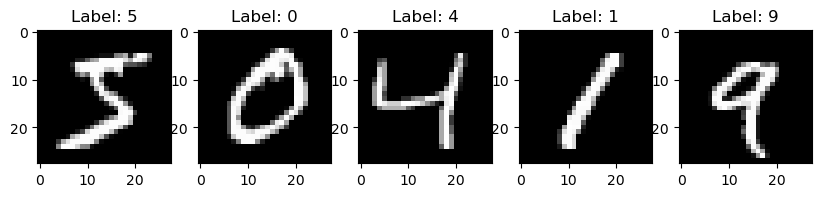

In [107]:
# First 5 Images
print("Displaying Frist 5 Images ans its Labels:")
fig, axes = plt.subplots(1, 5, figsize=(10, 3))
for i in range(5):
    raw_img = train_dataset.data[i] 
    label = train_dataset.targets[i]  
    axes[i].imshow(raw_img , cmap='gray')
    axes[i].set_title(f"Label: {label}")    
plt.show()

I am using .data to see the raw 0-255 pixels, ignoring the transform on training dataset.

### Building and training a CNN classifier on the MNIST training set.

In [108]:
# Define the convolution neural network architecture
class CNN_MNIST(nn.Module):
    def __init__(self):
        super(CNN_MNIST,self).__init__()
        self.conv1 = nn.Conv2d(1, 32, kernel_size = 3, padding = 1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size = 3, padding = 1)
        self.dropout1 = nn.Dropout2d(0.25)
        self.dropout2 = nn.Dropout(0.5)
        self.fc1 = nn.Linear(64*14*14, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        # Convolution layer
        x = nn.functional.relu(self.conv1(x))
        x = nn.functional.relu(self.conv2(x))

        # Pooling layer
        x = nn.functional.max_pool2d(self.dropout1(x),2)

        # Transition from 2D to 1D
        x = torch.flatten(x,1)
        
        # Apply dropout, then fc1, then the ReLU activation
        x = nn.functional.relu(self.fc1(self.dropout2(x)))
        
        # Final output
        x = self.fc2(x)
        return nn.functional.log_softmax(x,dim=1)

conv1 takes 1 input channel and creates 32 different filtered versions of the image to find edges and curves. Conv2 then takes those results and uses 64 filters to combine those lines into more complex shapes and patterns.

ReLU is the activation function that turns off negative values pixels so that the model only focuses on important features.

max_pool2d looks at 2x2 pixel squares and only keeps the maximum value and reduces the image size and keep only important features.

CNNs work in 2D, height and width, but standard classification layers fc1 work in 1D. So we transition 2D into 1D array.

log_softmax(x, dim=1)converts raw scores into log probabilities between 0 and 1.

In [115]:
# Initialize the model and optimizer
model = CNN_MNIST().to(device)
optimizer = optim.Adam(model.parameters())

print("Convolution neural network architecture", model)

Convolution neural network architecture CNN_MNIST(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (dropout1): Dropout2d(p=0.25, inplace=False)
  (dropout2): Dropout(p=0.5, inplace=False)
  (fc1): Linear(in_features=12544, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)


In [119]:
# Model training - training loop

model.train() # putting model in training mode

for epoch in range(3):

    # loading training data batch by batch from train_loader.
    for batch_idx, (data, target) in enumerate(train_loader):
        data, target = data.to(device), target.to(device)

        # clears previous gradients and do not accumulate before backpropagation.
        optimizer.zero_grad()
        output = model(data)
        loss = nn.functional.nll_loss(output, target)
        loss.backward()
        optimizer.step()

print("Model training is completed.")

Model training is completed.


3 epochs, it will go through the entire training dataset 3 times.

In [121]:
# Model testing
model.eval()
all_preds = []
all_targets = []

with torch.no_grad():
    for data, target in test_loader:
        data, target = data.to(device), target.to(device)
        output = model(data)
        pred = output.argmax(dim=1)
        all_preds.extend(pred.cpu().numpy())
        all_targets.extend(target.cpu().numpy())

print("Model testing is completed")

Model testing is completed


### Model accuracy

In [122]:
# Accuracy
accuracy = 100 * (np.array(all_preds) == np.array(all_targets)).sum() / len(all_targets)

print(f"CNN Model Accuracy: {accuracy:.2f}%")



CNN Model Accuracy: 99.23%


### Confusion Matrix

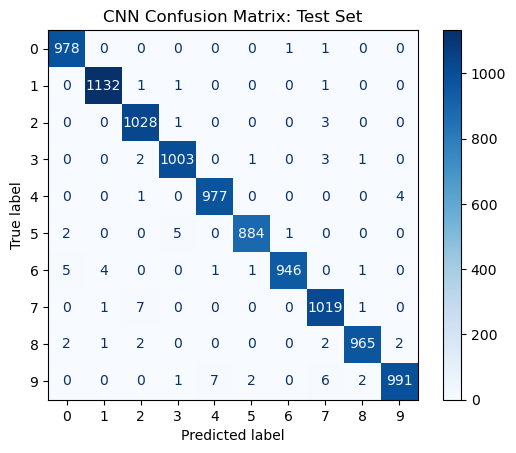

In [124]:
# Confusion matrix
cm = confusion_matrix(all_targets, all_preds)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=range(10))

disp.plot(cmap=plt.cm.Blues, values_format='d')

plt.title("CNN Confusion Matrix: Test Set")
plt.show()

CNN Model Accuracy for Image Classifier is 99.23%. This means 99.23% of the test images were correctly classified.

Only 77 predictions are wrong out of 10,000 test images. The model is very accurate across all classes, since most numbers are on the diagonal. Numbers outside the diagonal are the mistakes.

Results show that the CNN Image Classifier model learned the digit patterns correctly and generalizes well to test data.